# Hito 4 — Resultados definitivos, indagación y mapa de clusters
**Proyecto:** Segmentación de distritos del Perú según su estructura laboral y su relación con la pobreza monetaria
**Autores:** Thiago Ormeño, Daniela Eléspuru · Data Mining · Universidad del Pacífico

**Pregunta:** ¿qué perfiles laborales distintos existen entre los distritos del Perú y se asocian con distintos niveles de pobreza monetaria?
**Usuario:** Ministerio de Trabajo y Promoción del Empleo (MTPE).

Este cuaderno parte de la matriz analítica del Hito 2 (`output/matriz_analitica_distrital.csv`, 1 fila = 1 distrito) y cierra el proyecto:

1. **Configuración final y comparación definitiva** (K-means K = 3 frente a K = 2, K = 4, Ward, mezclas gaussianas y K-means ponderado por tamaño de muestra).
2. **Indagación** (respuesta a la retroalimentación del Hito 3): qué variables separan los grupos, si la asociación con la pobreza sobrevive dentro de cada región, si la informalidad aporta algo más allá de la ruralidad, quién está en la zona de transición, qué distritos se salen del patrón y qué pasa con los distritos de muestra chica.
3. **Mapa HTML** de clusters (Folium) y figura estática para el paper.
4. **Síntesis**: hallazgos con su evidencia, para la discusión y conclusiones.

Todas las tablas se guardan en `output/hito4/` y las figuras en `output/figuras/h4_*.png`. Semilla 42.

In [1]:
import json, os, urllib.request, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from scipy.stats import kruskal, spearmanr, mannwhitneyu
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold
from sklearn.neighbors import NearestNeighbors
import folium

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

BASE = Path(".")
OUT = BASE / "output" / "hito4"; OUT.mkdir(parents=True, exist_ok=True)
FIG = BASE / "output" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
GEO_DIR = BASE / "data_geo"; GEO_DIR.mkdir(exist_ok=True)
GEO_PATH = GEO_DIR / "peru_distrital_simple.geojson"
GEO_URL = "https://raw.githubusercontent.com/juaneladio/peru-geojson/master/peru_distrital_simple.geojson"

COLORES = {1: "#2b6cb0", 2: "#e0a100", 3: "#b83227"}
NOMBRES = {1: "1. Urbano asalariado", 2: "2. Mixto de transición", 3: "3. Rural agropecuario"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Datos y representación (resumen)
No se repite la limpieza (Hitos 1–2). Se usan las **11 variables laborales** de la ENAHO 2024; la pobreza 2018 **no entra** al clustering y se reserva como criterio externo. Ingreso faltante (67 distritos) → mediana; `StandardScaler` porque todas las técnicas usan distancia euclidiana.

In [2]:
df = pd.read_csv(BASE / "output" / "matriz_analitica_distrital.csv", dtype={"UBIGEO": str})
df["UBIGEO"] = df["UBIGEO"].str.zfill(6)

VARS = ["tasa_informalidad_pct", "tasa_subempleo_horas_pct", "log_ingreso_mensual",
        "horas_promedio_semana", "nivel_educativo_promedio", "tamano_empresa_promedio",
        "pct_rural", "pct_agropecuario", "pct_asalariados", "pct_mujeres", "edad_promedio"]
ETQ = {"tasa_informalidad_pct": "Informalidad %", "tasa_subempleo_horas_pct": "Subempleo horas %",
       "log_ingreso_mensual": "Log ingreso", "horas_promedio_semana": "Horas/semana",
       "nivel_educativo_promedio": "Educación (1-11)", "tamano_empresa_promedio": "Tamaño empresa (1-5)",
       "pct_rural": "Rural %", "pct_agropecuario": "Agro %", "pct_asalariados": "Asalariados %",
       "pct_mujeres": "Mujeres %", "edad_promedio": "Edad"}

X_raw = df[VARS].copy()
X_raw = X_raw.fillna(X_raw.median())
X = StandardScaler().fit_transform(X_raw)
pobreza = df["pobreza_pct"].values
n = len(df)
print(f"Matriz: {n} distritos x {len(VARS)} variables | faltantes imputados: {df[VARS].isna().sum().sum()}")
print(f"Distritos con < 10 encuestados: {(df['n_muestra'] < 10).sum()}")

Matriz: 1270 distritos x 11 variables | faltantes imputados: 67
Distritos con < 10 encuestados: 105


## 2. Funciones de evaluación
- **Internas:** Silhouette (↑), Davies-Bouldin (↓), Calinski-Harabasz (↑).
- **Externa:** ε² de Kruskal-Wallis de la pobreza según el grupo (↑; la pobreza no participa del agrupamiento).
- **Estabilidad:** ARI medio entre la partición completa y 30 refits sobre submuestras del 80 %.
- Todas las particiones se evalúan en el **mismo espacio** (11 variables estandarizadas).

In [3]:
def renumerar(labels):
    # 1 = menos rural ... K = más rural, para que los números signifiquen siempre lo mismo
    orden = pd.Series(X_raw["pct_rural"].values).groupby(labels).mean().sort_values().index
    mapa = {old: new for new, old in enumerate(orden, start=1)}
    return np.array([mapa[l] for l in labels])

def eps2(labels, y=pobreza):
    grupos = [y[labels == g] for g in np.unique(labels)]
    H = kruskal(*grupos).statistic
    k = len(grupos)
    return (H - k + 1) / (len(y) - k)

def ajustar(metodo, k, Xm, w=None, seed=SEED):
    if metodo == "kmeans":
        m = KMeans(n_clusters=k, n_init=10, random_state=seed)
        return m.fit_predict(Xm, sample_weight=w)
    if metodo == "ward":
        return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xm)
    if metodo == "gmm":
        return GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=seed).fit_predict(Xm)

def estabilidad(metodo, k, labels_full, w=None, reps=30):
    aris = []
    for r in range(reps):
        idx = rng.choice(n, size=int(0.8 * n), replace=False)
        lab = ajustar(metodo, k, X[idx], None if w is None else w[idx], seed=SEED + r + 1)
        aris.append(adjusted_rand_score(labels_full[idx], lab))
    return np.mean(aris)

def evaluar(nombre, metodo, k, w=None):
    lab = renumerar(ajustar(metodo, k, X, w))
    tam = np.bincount(lab)[1:]
    return lab, dict(configuracion=nombre, K=k,
                     silhouette=silhouette_score(X, lab), davies_bouldin=davies_bouldin_score(X, lab),
                     calinski_harabasz=calinski_harabasz_score(X, lab), eps2_pobreza=eps2(lab),
                     ari_bootstrap=estabilidad(metodo, k, lab, w), grupo_min=tam.min(),
                     tamanos="/".join(map(str, tam)))

## 3. Comparación definitiva de configuraciones
Respecto del Hito 3 se agregan dos alternativas que quedaron pendientes:
- **Mezclas gaussianas (GMM, K = 3):** asignación suave; permite medir la incertidumbre del grupo intermedio.
- **K-means ponderado por `n_muestra`:** da menos peso a distritos con pocos encuestados (tasas ruidosas).

In [4]:
w_muestra = np.sqrt(df["n_muestra"].values)   # peso ~ inverso del error estándar de una tasa
configs = [("K-means K=2", "kmeans", 2, None), ("K-means K=3 (final)", "kmeans", 3, None),
           ("K-means K=4", "kmeans", 4, None), ("Ward K=3", "ward", 3, None),
           ("GMM K=3", "gmm", 3, None), ("K-means K=3 ponderado n", "kmeans", 3, w_muestra)]
etiquetas, filas = {}, []
for nombre, metodo, k, w in configs:
    lab, fila = evaluar(nombre, metodo, k, w)
    etiquetas[nombre] = lab; filas.append(fila)

final = etiquetas["K-means K=3 (final)"]
comp = pd.DataFrame(filas)
comp["ari_vs_final"] = [adjusted_rand_score(final, etiquetas[c]) for c in comp["configuracion"]]
comp = comp.round(3)
comp.to_csv(OUT / "t01_comparacion_final.csv", index=False)
comp

,configuracion,K,silhouette,davies_bouldin,calinski_harabasz,eps2_pobreza,ari_bootstrap,grupo_min,tamanos,ari_vs_final
0,K-means K=2,2,0.289,1.314,626.994,0.343,0.988,557,557/713,0.439
1,K-means K=3 (final),3,0.170,1.867,417.272,0.398,0.924,343,343/430/497,1.000
2,K-means K=4,4,0.159,1.849,334.738,0.398,0.807,157,270/392/157/451,0.553
3,Ward K=3,3,0.130,2.090,356.167,0.358,0.564,258,399/258/613,0.524
4,GMM K=3,3,0.097,2.156,248.656,0.324,0.864,235,235/398/637,0.327
5,K-means K=3 ponderado n,3,0.170,1.851,416.292,0.400,0.900,326,326/407/537,0.869


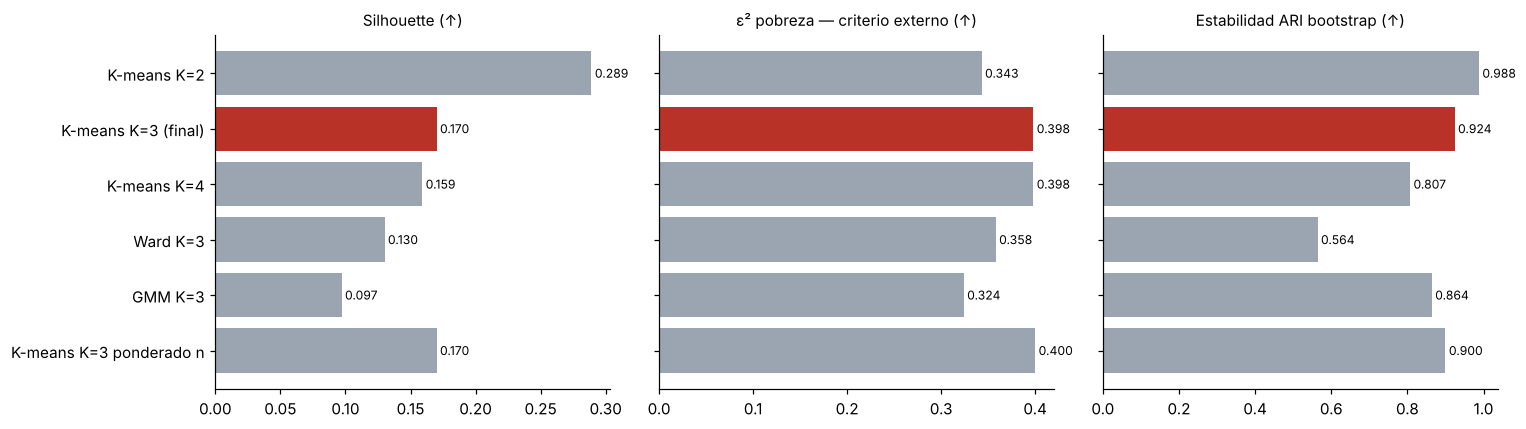

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (col, tit) in zip(axes, [("silhouette", "Silhouette (↑)"), ("eps2_pobreza", "ε² pobreza — criterio externo (↑)"),
                                  ("ari_bootstrap", "Estabilidad ARI bootstrap (↑)")]):
    colores = ["#b83227" if "final" in c else "#9aa5b1" for c in comp["configuracion"]]
    ax.barh(comp["configuracion"], comp[col], color=colores)
    for i, v in enumerate(comp[col]): ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
    ax.set_title(tit, fontsize=10); ax.invert_yaxis()
    if ax is not axes[0]: ax.set_yticklabels([])
plt.tight_layout(); plt.savefig(FIG / "h4_01_comparacion_final.png", bbox_inches="tight"); plt.show()

**Lectura — configuración final.** Se mantiene **K-means con K = 3 sobre las 11 variables estandarizadas**:
- Es la que más se asocia con la pobreza sin haberla usado (ε² = 0.398; empatada con K = 4 y con la versión ponderada, 0.400) y conserva estabilidad alta (ARI bootstrap 0.92).
- K = 2 tiene mejor silhouette (0.289) y estabilidad (0.988), pero solo separa urbano de rural y pierde asociación con la pobreza (0.343).
- K = 4 no agrega asociación con la pobreza (0.398) y es menos estable (0.81).
- Ward (ARI bootstrap 0.56) y GMM (silhouette 0.097, ε² 0.324) quedan por debajo en todos los criterios.
- **Ponderar por tamaño de muestra casi no cambia nada** (ARI 0.87 con la final, ε² 0.400): la solución no depende de los distritos con pocos encuestados.
- La silhouette sigue baja (0.17): los distritos forman un **gradiente continuo**; los grupos son una segmentación útil, no tipos naturales.

## 4. Perfil de la configuración final (K-means, K = 3)

In [6]:
df["cluster"] = final
df["cluster_nombre"] = df["cluster"].map(NOMBRES)
sil_i = silhouette_samples(X, final); df["silhouette"] = sil_i

perfil = df.groupby("cluster").agg(
    distritos=("UBIGEO", "size"), poblacion_mill=("POBLACION_2020", lambda s: s.sum() / 1e6),
    informalidad=("tasa_informalidad_pct", "mean"), ingreso_mensual=("ingreso_mensual_w", "mean"),
    subempleo=("tasa_subempleo_horas_pct", "mean"), horas=("horas_promedio_semana", "mean"),
    educacion=("nivel_educativo_promedio", "mean"), tamano_empresa=("tamano_empresa_promedio", "mean"),
    rural=("pct_rural", "mean"), agro=("pct_agropecuario", "mean"), asalariados=("pct_asalariados", "mean"),
    mujeres=("pct_mujeres", "mean"), edad=("edad_promedio", "mean"),
    pobreza_media=("pobreza_pct", "mean"), pobreza_mediana=("pobreza_pct", "median"),
    pobreza_p25=("pobreza_pct", lambda s: s.quantile(.25)), pobreza_p75=("pobreza_pct", lambda s: s.quantile(.75)),
    n_muestra_mediana=("n_muestra", "median"), silhouette=("silhouette", "mean")).round(2)
perfil.index = perfil.index.map(NOMBRES)
perfil.T.to_csv(OUT / "t02_perfil_clusters.csv")
# población en pobreza (aprox.) = población 2020 x tasa de pobreza 2018
df["pobres_aprox"] = df["POBLACION_2020"] * df["pobreza_pct"] / 100
print("Pobres aprox. por cluster (millones):", (df.groupby("cluster")["pobres_aprox"].sum() / 1e6).round(2).to_dict())
print(f"ε² pobreza (K-means K=3): {eps2(final):.3f}")
perfil.T

Pobres aprox. por cluster (millones): {1: 3.14, 2: 1.73, 3: 1.34}
ε² pobreza (K-means K=3): 0.398


cluster,1. Urbano asalariado,2. Mixto de transición,3. Rural agropecuario
distritos,343.00,430.00,497.00
poblacion_mill,23.01,5.48,2.84
informalidad,60.25,84.90,97.70
ingreso_mensual,1853.99,1324.21,854.54
subempleo,7.21,7.53,8.39
horas,41.66,37.63,31.97
educacion,6.68,5.48,4.59
tamano_empresa,2.05,1.47,1.12
rural,13.23,55.11,93.38
agro,16.73,47.06,80.04


## 5. Indagación

### 5.1 ¿Qué variables separan realmente los grupos?
Para cada variable se calcula η² (proporción de su varianza explicada por el cluster). Luego se entrena un **árbol de decisión de profundidad 2–3** que imita la partición: si pocas reglas la reproducen, el MTPE puede clasificar un distrito nuevo sin correr K-means.

 profundidad  accuracy_cv
           1        0.587
           2        0.801
           3        0.797
|--- Agro % <= 61.3
|   |--- Informalidad % <= 73.3
|   |   |--- class: 1
|   |--- Informalidad % >  73.3
|   |   |--- class: 2
|--- Agro % >  61.3
|   |--- Asalariados % <= 33.8
|   |   |--- class: 3
|   |--- Asalariados % >  33.8
|   |   |--- class: 2



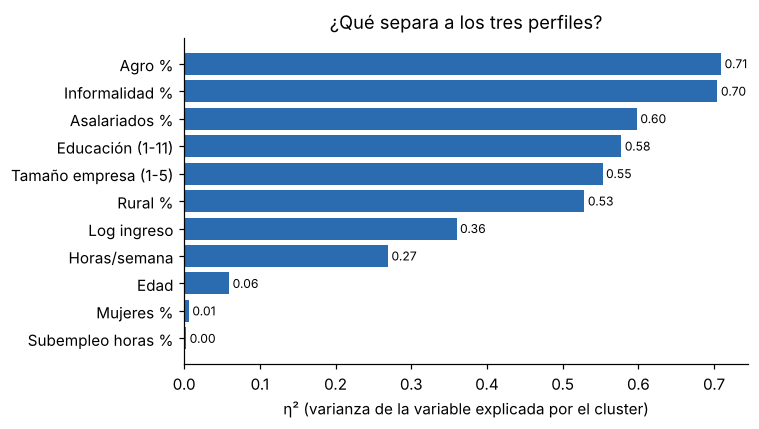

,variable,eta2_cluster
7,Agro %,0.709334
0,Informalidad %,0.704474
8,Asalariados %,0.598026
4,Educación (1-11),0.577492
5,Tamaño empresa (1-5),0.552692
6,Rural %,0.528711
2,Log ingreso,0.359856
3,Horas/semana,0.269288
10,Edad,0.059427
9,Mujeres %,0.006242


In [7]:
def eta2(y, g):
    m = y.mean(); ssb = sum(len(y[g == k]) * (y[g == k].mean() - m) ** 2 for k in np.unique(g))
    return ssb / ((y - m) ** 2).sum()

imp = pd.DataFrame({"variable": [ETQ[v] for v in VARS],
                    "eta2_cluster": [eta2(X[:, j], final) for j in range(len(VARS))]}).sort_values("eta2_cluster", ascending=False)
imp.to_csv(OUT / "t03_eta2_variables.csv", index=False)

arbol_res = []
for prof in [1, 2, 3]:
    tree = DecisionTreeClassifier(max_depth=prof, random_state=SEED)
    acc_cv = cross_val_score(tree, X_raw, final, cv=KFold(5, shuffle=True, random_state=SEED)).mean()
    arbol_res.append({"profundidad": prof, "accuracy_cv": round(acc_cv, 3)})
arbol_res = pd.DataFrame(arbol_res); arbol_res.to_csv(OUT / "t04_arbol_surrogado.csv", index=False)
tree2 = DecisionTreeClassifier(max_depth=2, random_state=SEED).fit(X_raw, final)
reglas = export_text(tree2, feature_names=[ETQ[v] for v in VARS], decimals=1)
(OUT / "reglas_arbol_profundidad2.txt").write_text(reglas, encoding="utf-8")
print(arbol_res.to_string(index=False)); print(reglas)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp["variable"], imp["eta2_cluster"], color="#2b6cb0"); ax.invert_yaxis()
for i, v in enumerate(imp["eta2_cluster"]): ax.text(v, i, f" {v:.2f}", va="center", fontsize=8)
ax.set_xlabel("η² (varianza de la variable explicada por el cluster)"); ax.set_title("¿Qué separa a los tres perfiles?")
plt.tight_layout(); plt.savefig(FIG / "h4_02_eta2_variables.png", bbox_inches="tight"); plt.show()
imp

**Lectura — qué separa los grupos.** Los perfiles se definen por la **estructura productiva**: % agropecuario (η² 0.71), informalidad (0.70), % asalariados (0.60), educación (0.58), tamaño de empresa (0.55) y ruralidad (0.53). Subempleo por horas, % de mujeres y edad casi no aportan (η² < 0.06): la segmentación no captura esas dimensiones.
Un **árbol de solo 2 niveles reproduce el 80 % de las asignaciones** (validación cruzada) con tres variables: % agropecuario (corte ≈ 61 %), informalidad (≈ 73 %) y % asalariados (≈ 34 %). Para el MTPE esto se traduce en una regla simple para clasificar un distrito sin correr el modelo.

### 5.2 ¿La asociación con la pobreza es solo geografía (Costa vs. Sierra)?
Si los clusters solo repitieran la región natural, no aportarían nada al MTPE. Se compara el ε² de la **región** con el del **cluster**, y se mide el ε² del cluster **dentro de cada región** (Kruskal-Wallis).

In [8]:
reg = df["region_natural"].values
filas = [{"region": "Perú (todas)", "distritos": n, "eps2_cluster": eps2(final), "eps2_region": eps2(pd.factorize(reg)[0])}]
for r in ["Costa", "Sierra", "Selva"]:
    m = reg == r
    sub = final[m]
    filas.append({"region": r, "distritos": m.sum(), "eps2_cluster": eps2(sub, pobreza[m]),
                  "eps2_region": np.nan,
                  **{f"pobreza_mediana_c{k}": np.median(pobreza[m][sub == k]) if (sub == k).sum() >= 5 else np.nan for k in [1, 2, 3]},
                  **{f"n_c{k}": int((sub == k).sum()) for k in [1, 2, 3]}})
por_region = pd.DataFrame(filas).round(3)
por_region.to_csv(OUT / "t05_pobreza_cluster_por_region.csv", index=False)
por_region

,region,distritos,eps2_cluster,eps2_region,pobreza_mediana_c1,pobreza_mediana_c2,pobreza_mediana_c3,n_c1,n_c2,n_c3
0,Perú (todas),1270,0.398,0.274,NaN,NaN,NaN,NaN,NaN,NaN
1,Costa,265,0.175,NaN,13.242,18.813,42.283,153.0,88.0,24.0
2,Sierra,719,0.239,NaN,22.179,36.628,44.958,115.0,232.0,372.0
3,Selva,239,0.201,NaN,15.387,30.011,38.942,29.0,109.0,101.0


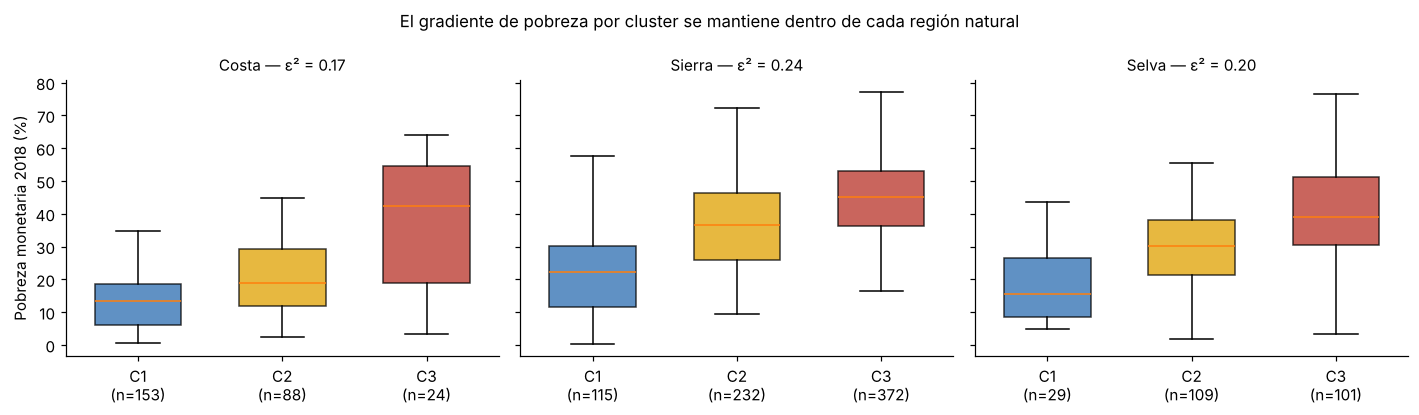

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, r in zip(axes, ["Costa", "Sierra", "Selva"]):
    m = reg == r
    datos = [pobreza[m & (final == k)] for k in [1, 2, 3]]
    bp = ax.boxplot(datos, patch_artist=True, widths=.6, showfliers=False)
    for p, k in zip(bp["boxes"], [1, 2, 3]): p.set_facecolor(COLORES[k]); p.set_alpha(.75)
    ax.set_xticks([1, 2, 3], [f"C{k}\n(n={len(d)})" for k, d in zip([1, 2, 3], datos)])
    ax.set_title(f"{r} — ε² = {por_region.set_index('region').loc[r, 'eps2_cluster']:.2f}", fontsize=10)
axes[0].set_ylabel("Pobreza monetaria 2018 (%)")
plt.suptitle("El gradiente de pobreza por cluster se mantiene dentro de cada región natural", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "h4_03_pobreza_cluster_region.png", bbox_inches="tight"); plt.show()

**Lectura — no es solo geografía.** El cluster explica más variación de la pobreza que la región natural (ε² 0.398 frente a 0.274) y **el gradiente 1 < 2 < 3 se repite dentro de Costa, Sierra y Selva** (ε² entre 0.17 y 0.24). Dentro de la Sierra, por ejemplo, la pobreza mediana sube de 22.2 % (C1) a 36.6 % (C2) y 45.0 % (C3). El perfil laboral aporta información que la región no da. En la Costa el cluster 3 tiene solo 24 distritos (lectura menos firme).

### 5.3 ¿La informalidad aporta algo más allá de la ruralidad?
La correlación informalidad–pobreza (+0.58 en el Hito 2) podría ser solo ruralidad. Se mide:
- la correlación de Spearman informalidad–pobreza **dentro** de cada cluster;
- regresiones lineales de la pobreza con validación cruzada (R² CV de 5 pliegues): solo cluster, solo ruralidad, solo informalidad, ruralidad + informalidad, y las 11 variables. Coeficientes estandarizados del modelo completo.
Es asociación (pobreza 2018 vs. empleo 2024), no causalidad.

In [10]:
dentro = []
for k in [1, 2, 3]:
    m = final == k
    rho, p = spearmanr(df.loc[m, "tasa_informalidad_pct"], df.loc[m, "pobreza_pct"])
    rho_i, p_i = spearmanr(X_raw.loc[m, "log_ingreso_mensual"], df.loc[m, "pobreza_pct"])
    dentro.append({"cluster": NOMBRES[k], "rho_informalidad_pobreza": rho, "p_inf": p,
                   "rho_ingreso_pobreza": rho_i, "p_ing": p_i})
rho_all = spearmanr(df["tasa_informalidad_pct"], df["pobreza_pct"])[0]
dentro.append({"cluster": "Todos", "rho_informalidad_pobreza": rho_all, "p_inf": np.nan,
               "rho_ingreso_pobreza": spearmanr(X_raw["log_ingreso_mensual"], df["pobreza_pct"])[0], "p_ing": np.nan})
dentro = pd.DataFrame(dentro).round(3); dentro.to_csv(OUT / "t06_correlacion_dentro_cluster.csv", index=False)
print(dentro.to_string(index=False))

cv = KFold(5, shuffle=True, random_state=SEED)
dummies = pd.get_dummies(df["cluster"], prefix="c", drop_first=True).astype(float)
Xz = pd.DataFrame(X, columns=VARS)
modelos = {"Solo cluster (2 dummies)": dummies,
           "Solo % rural": Xz[["pct_rural"]],
           "Solo informalidad": Xz[["tasa_informalidad_pct"]],
           "% rural + informalidad": Xz[["pct_rural", "tasa_informalidad_pct"]],
           "Cluster + 11 variables": pd.concat([dummies, Xz], axis=1),
           "11 variables": Xz}
r2 = pd.DataFrame([{"modelo": k, "R2_cv": cross_val_score(LinearRegression(), v, pobreza, cv=cv, scoring="r2").mean()}
                   for k, v in modelos.items()]).round(3)
r2.to_csv(OUT / "t07_r2_modelos_pobreza.csv", index=False)
print(r2.to_string(index=False))

lr = LinearRegression().fit(Xz, (pobreza - pobreza.mean()) / pobreza.std())
coef = pd.DataFrame({"variable": [ETQ[v] for v in VARS], "beta_estandarizado": lr.coef_}).round(3)
coef = coef.reindex(coef["beta_estandarizado"].abs().sort_values(ascending=False).index)
coef.to_csv(OUT / "t08_coeficientes_pobreza.csv", index=False)
coef

               cluster  rho_informalidad_pobreza  p_inf  rho_ingreso_pobreza  p_ing
  1. Urbano asalariado                     0.275  0.000               -0.227  0.000
2. Mixto de transición                     0.127  0.008               -0.013  0.781
 3. Rural agropecuario                    -0.026  0.557               -0.020  0.654
                 Todos                     0.582    NaN               -0.450    NaN
                  modelo  R2_cv
Solo cluster (2 dummies)  0.383
            Solo % rural  0.290
       Solo informalidad  0.334
  % rural + informalidad  0.392
  Cluster + 11 variables  0.496
            11 variables  0.496


,variable,beta_estandarizado
4,Educación (1-11),-0.358
8,Asalariados %,-0.225
5,Tamaño empresa (1-5),0.192
10,Edad,-0.168
6,Rural %,0.156
0,Informalidad %,0.137
3,Horas/semana,-0.080
7,Agro %,0.061
9,Mujeres %,0.017
1,Subempleo horas %,-0.012


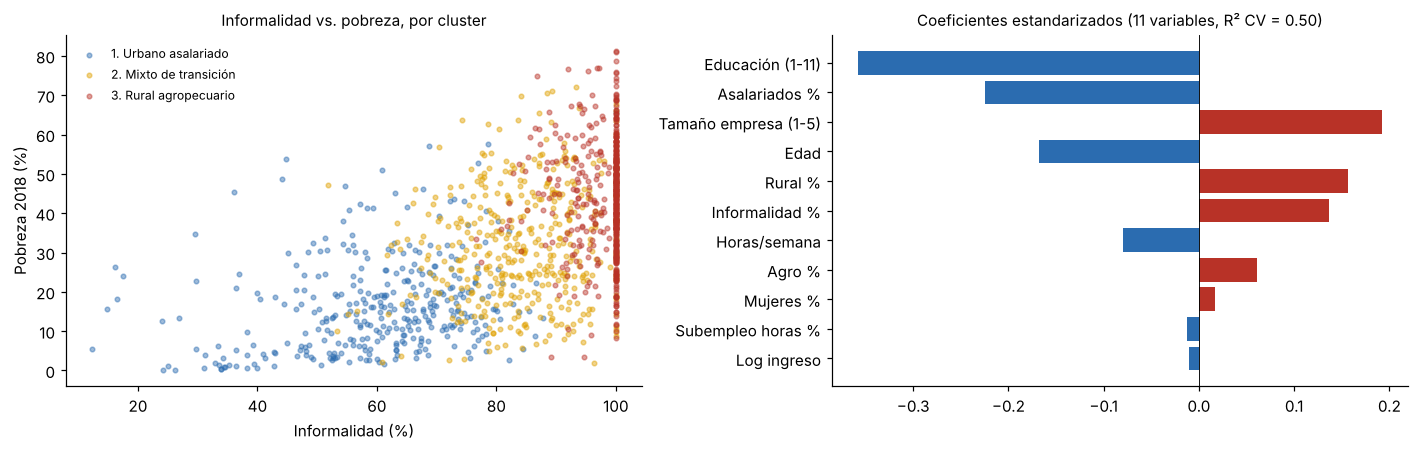

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
for k in [1, 2, 3]:
    m = final == k
    ax.scatter(df.loc[m, "tasa_informalidad_pct"], df.loc[m, "pobreza_pct"], s=9, alpha=.45, color=COLORES[k], label=NOMBRES[k])
ax.set_xlabel("Informalidad (%)"); ax.set_ylabel("Pobreza 2018 (%)"); ax.legend(fontsize=8, frameon=False)
ax.set_title("Informalidad vs. pobreza, por cluster", fontsize=10)
ax = axes[1]
ax.barh(coef["variable"], coef["beta_estandarizado"], color=["#b83227" if b > 0 else "#2b6cb0" for b in coef["beta_estandarizado"]])
ax.invert_yaxis(); ax.axvline(0, color="k", lw=.6)
ax.set_title(f"Coeficientes estandarizados (11 variables, R² CV = {r2.set_index('modelo').loc['11 variables','R2_cv']:.2f})", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "h4_04_informalidad_vs_rural.png", bbox_inches="tight"); plt.show()

**Lectura — ¿qué papel juega la informalidad?**
- La correlación informalidad–pobreza es fuerte entre todos los distritos (ρ = 0.58), pero **se debilita mucho dentro de cada perfil**: 0.28 en el urbano, 0.13 en el mixto y **≈ 0 en el rural** (ρ = −0.03, p = 0.56). La asociación es sobre todo *entre* perfiles: la informalidad marca el tipo de economía local más que la pobreza distrito por distrito. En el perfil rural la informalidad está saturada (97.7 %) y ya no discrimina.
- Lo mismo ocurre con el ingreso (−0.45 en total; ≈ 0 dentro de los perfiles 2 y 3).
- Modelos de la pobreza (R² con validación cruzada): solo el cluster 0.38; solo informalidad 0.33; solo ruralidad 0.29; ruralidad + informalidad 0.39; las 11 variables 0.50. **Tres grupos resumen tres cuartas partes de lo que explican las 11 variables**, y agregar el cluster a las variables no suma nada (0.50).
- En el modelo completo el mayor coeficiente es la **educación** (−0.36), seguida de % asalariados (−0.23); la informalidad retiene un efecto propio menor (+0.14) tras controlar el resto. El signo positivo del tamaño de empresa refleja colinealidad con educación y asalariados: no debe leerse aisladamente.
- Todo esto es asociación (pobreza 2018 frente a empleo 2024), no causalidad.

### 5.4 La zona de transición (cluster 2)
Para cada distrito se mide el **margen relativo** entre su centroide y el segundo más cercano, `margen = (d2 − d1) / d2` (0 = equidistante, 1 = pegado a su centroide), junto con su silhouette. Un distrito es *ambiguo* si su silhouette < 0 o su margen < 0.10. (La GMM se probó en la sección 3, pero genera otra partición —ARI 0.33 con la final— y probabilidades casi siempre ≈ 1, por lo que no sirve para medir la incertidumbre de K-means.)

In [12]:
Xz_df = pd.DataFrame(X, columns=VARS)
km3 = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X)
mapa = {r: f for r, f in zip(km3.labels_, final)}
cent = {mapa[i]: km3.cluster_centers_[i] for i in range(3)}
d = np.column_stack([np.linalg.norm(X - cent[k], axis=1) for k in [1, 2, 3]])
d_ord = np.sort(d, axis=1)
df["margen"] = (d_ord[:, 1] - d_ord[:, 0]) / d_ord[:, 1]
df["ambiguo"] = (df["silhouette"] < 0) | (df["margen"] < 0.10)

amb = df.groupby("cluster_nombre").agg(distritos=("UBIGEO", "size"), ambiguos=("ambiguo", "sum"),
                                       pct_ambiguos=("ambiguo", "mean"), sil_negativa=("silhouette", lambda s: (s < 0).sum()),
                                       margen_medio=("margen", "mean")).round(3)
amb.to_csv(OUT / "t09_ambiguedad_por_cluster.csv")
print(amb)

# ¿Hacia dónde "tiran" los ambiguos del cluster 2? -> segundo centroide más cercano
segundo = np.argsort(d, axis=1)[:, 1] + 1
m2 = (final == 2) & df["ambiguo"].values
print("Cluster 2 ambiguos -> segundo grupo más cercano:", pd.Series(segundo[m2]).value_counts().to_dict())

comp_amb = df[final == 2].groupby("ambiguo")[["pobreza_pct", "pct_rural", "tasa_informalidad_pct",
                                               "ingreso_mensual_w", "n_muestra"]].median().round(1)
comp_amb.index = ["Núcleo del cluster 2", "Ambiguos del cluster 2"]
comp_amb.to_csv(OUT / "t10_cluster2_nucleo_vs_ambiguo.csv")
comp_amb

                        distritos  ambiguos  pct_ambiguos  sil_negativa  margen_medio
cluster_nombre                                                                       
1. Urbano asalariado          343        39         0.114             0         0.385
2. Mixto de transición        430       111         0.258            32         0.224
3. Rural agropecuario         497        57         0.115            14         0.280
Cluster 2 ambiguos -> segundo grupo más cercano: {3: 63, 1: 48}


,pobreza_pct,pct_rural,tasa_informalidad_pct,ingreso_mensual_w,n_muestra
Núcleo del cluster 2,30.6,48.0,84.6,1260.7,28.0
Ambiguos del cluster 2,31.9,57.1,86.0,1209.5,16.0


**Lectura — zona de transición.** El cluster 2 concentra la ambigüedad: 26 % de sus distritos es ambiguo (frente a 11 % en los otros dos) y tiene 32 de los 46 distritos con silhouette negativa. Sus ambiguos se reparten hacia ambos lados (63 cerca del rural y 48 cerca del urbano), lo que confirma que es un **tramo intermedio del gradiente** y no un grupo propio. Los ambiguos tienen **menos encuestados** (mediana 16 frente a 28): parte de la ambigüedad es ruido muestral, no una economía distinta. Para el MTPE: estos distritos deben revisarse caso por caso antes de asignarles una política «tipo».

### 5.5 Distritos que se salen del patrón (para focalización)
Se compara la pobreza observada con la que «corresponde» a su perfil laboral (regresión con las 11 variables, predicción fuera de muestra por validación cruzada). Los residuos grandes identifican:
- **pobreza oculta:** distritos más pobres de lo que su empleo sugiere;
- **mejor de lo esperado:** casos que podrían servir de referencia.
Solo se listan distritos con ≥ 20 encuestados (para que el perfil laboral sea confiable).

In [13]:
from sklearn.model_selection import cross_val_predict
df["pobreza_esperada"] = cross_val_predict(LinearRegression(), Xz_df, pobreza, cv=cv)
df["residuo_pobreza"] = df["pobreza_pct"] - df["pobreza_esperada"]
conf = df["n_muestra"] >= 20
cols = ["UBIGEO", "DEPARTAMENTO", "PROVINCIA", "DISTRITO", "cluster", "n_muestra", "tasa_informalidad_pct",
        "pct_rural", "pobreza_pct", "pobreza_esperada", "residuo_pobreza"]
ocultos = df[conf].nlargest(15, "residuo_pobreza")[cols].round(1)
mejores = df[conf].nsmallest(15, "residuo_pobreza")[cols].round(1)
ocultos.to_csv(OUT / "t11_pobreza_oculta_top15.csv", index=False)
mejores.to_csv(OUT / "t12_mejor_de_lo_esperado_top15.csv", index=False)
umbral = df["residuo_pobreza"].std()
df["atipico"] = np.where(conf & (df["residuo_pobreza"] > 1.5 * umbral), "pobreza oculta",
                np.where(conf & (df["residuo_pobreza"] < -1.5 * umbral), "mejor de lo esperado", ""))
print("DE del residuo:", round(umbral, 1), "pp | atípicos:", df["atipico"].value_counts().to_dict())
print("Pobreza oculta por región:", df[df.atipico == "pobreza oculta"]["region_natural"].value_counts().to_dict())
print("Pobreza oculta por cluster:", df[df.atipico == "pobreza oculta"]["cluster"].value_counts().to_dict())
ocultos

DE del residuo: 12.3 pp | atípicos: {'': 1196, 'pobreza oculta': 40, 'mejor de lo esperado': 34}
Pobreza oculta por región: {'Sierra': 27, 'Selva': 10, 'Costa': 3}
Pobreza oculta por cluster: {3: 19, 2: 15, 1: 6}


,UBIGEO,DEPARTAMENTO,PROVINCIA,DISTRITO,cluster,n_muestra,tasa_informalidad_pct,pct_rural,pobreza_pct,pobreza_esperada,residuo_pobreza
1026,190206,Pasco,Daniel Alcides Carrión,Santa Ana De Tusi,2,40,93.3,37.1,72.2,30.6,41.5
366,060604,Cajamarca,Cutervo,Cujillo,3,24,92.0,100.0,76.6,39.0,37.7
353,060410,Cajamarca,Chota,Lajas,2,30,89.4,41.0,71.1,35.5,35.5
570,100401,Huánuco,Huacaybamba,Huacaybamba,1,25,54.7,14.5,46.9,14.9,32.1
104,021503,Áncash,Pallasca,Conchucos,2,20,78.5,32.0,62.7,31.1,31.6
331,060106,Cajamarca,Cajamarca,Jesús,2,53,88.5,69.7,70.5,39.2,31.3
330,060105,Cajamarca,Cajamarca,Encañada,3,28,86.9,100.0,74.9,44.5,30.5
332,060107,Cajamarca,Cajamarca,Llacanora,2,30,74.2,100.0,63.6,34.9,28.8
286,050410,Ayacucho,Huanta,Uchuraccay,3,20,100.0,100.0,81.3,52.5,28.7
398,061201,Cajamarca,San Pablo,San Pablo,3,48,94.4,73.6,65.4,36.8,28.7


In [14]:
mejores

,UBIGEO,DEPARTAMENTO,PROVINCIA,DISTRITO,cluster,n_muestra,tasa_informalidad_pct,pct_rural,pobreza_pct,pobreza_esperada,residuo_pobreza
992,170303,Madre De Dios,Tahuamanu,Tahuamanu,3,33,89.2,100.0,3.4,37.1,-33.7
1184,220505,San Martín,Lamas,Cuñumbuqui,3,26,100.0,100.0,15.0,47.2,-32.2
635,110303,Ica,Nasca,El Ingenio,2,24,72.0,100.0,2.6,29.2,-26.6
808,140119,Lambayeque,Chiclayo,Pucala,2,23,73.9,54.1,12.5,37.4,-24.8
584,100607,Huánuco,Leoncio Prado,Pucayacu,3,27,100.0,100.0,23.7,48.4,-24.6
1268,250305,Ucayali,Padre Abad,Alexander Von Humboldt,2,30,89.2,28.8,12.9,37.5,-24.6
988,170203,Madre De Dios,Manu,Madre De Dios,2,59,96.4,73.0,1.9,26.2,-24.3
1266,250303,Ucayali,Padre Abad,Curimaná,3,42,95.9,33.2,9.0,32.0,-23.0
640,110403,Ica,Palpa,Río Grande,2,26,74.6,100.0,2.8,25.4,-22.6
1179,220405,San Martín,Huallaga,Sacanche,3,32,90.5,100.0,19.3,41.8,-22.5


**Lectura — atípicos.** La pobreza observada se desvía de la esperada por su perfil laboral con una desviación estándar de 12.3 puntos. Entre los distritos con ≥ 20 encuestados, 40 tienen **pobreza oculta** (> 1.5 DE por encima de lo esperado) y 34 están **mejor de lo esperado**.
- La pobreza oculta se concentra en la **Sierra norte (Cajamarca)**: 9 de los 15 casos más extremos están ahí (Cujillo, Lajas, Jesús, Encañada, Llacanora, San Pablo…). El perfil laboral no captura toda la pobreza de esa zona: hay factores fuera del empleo (acceso a servicios, productividad agrícola, geografía).
- Los casos *mejor de lo esperado* están en la **Selva baja (Madre de Dios, Ucayali, San Martín)** y en valles costeros de Ica: empleo rural e informal, pero con pobreza baja (economías extractivas o agroexportadoras).
- Además, son los casos donde el **desfase 2018–2024** pesa más: un residuo grande puede reflejar cambios reales en esos seis años.

### 5.6 Calidad de la muestra: ¿los resultados dependen de distritos con pocos encuestados?
Se repite el análisis con umbrales mínimos de encuestados y con K-means ponderado por √n.

In [15]:
rob = []
for umbral_n in [3, 10, 20, 30]:
    m = df["n_muestra"].values >= umbral_n
    Xm = StandardScaler().fit_transform(X_raw[m])
    lab_m = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(Xm)
    rob.append({"min_encuestados": umbral_n, "distritos": int(m.sum()),
                "ari_vs_final": adjusted_rand_score(final[m], lab_m),
                "eps2_pobreza": eps2(lab_m, pobreza[m]),
                "silhouette": silhouette_score(Xm, lab_m),
                "pct_retenidos_c1": (final[m] == 1).mean() * 100, "pct_retenidos_c3": (final[m] == 3).mean() * 100,
                "eps2_particion_final": eps2(final[m], pobreza[m]),
                "rho_informalidad_pobreza": spearmanr(df.loc[m, "tasa_informalidad_pct"], df.loc[m, "pobreza_pct"])[0]})
rob = pd.DataFrame(rob).round(3); rob.to_csv(OUT / "t13_robustez_muestra.csv", index=False)
rob

,min_encuestados,distritos,ari_vs_final,eps2_pobreza,silhouette,pct_retenidos_c1,pct_retenidos_c3,eps2_particion_final,rho_informalidad_pobreza
0,3,1270,1.000,0.398,0.170,27.008,39.134,0.398,0.582
1,10,1165,0.956,0.426,0.175,26.609,39.399,0.426,0.603
2,20,715,0.668,0.505,0.182,35.804,28.531,0.506,0.687
3,30,500,0.395,0.519,0.178,44.400,19.800,0.516,0.701


**Lectura — calidad de muestra.** Si se exige más encuestados por distrito, **la asociación con la pobreza se fortalece**: ε² sube de 0.40 a 0.51 (n ≥ 20) y la correlación informalidad–pobreza de 0.58 a 0.70. El ruido de las tasas distritales con muestra chica *atenúa* la relación, así que los resultados del paper son conservadores. La partición reestimada cambia con n ≥ 20 (ARI 0.67) porque cae la proporción de distritos rurales (de 39 % a 29 %: son los de menos encuestados), no porque el patrón desaparezca; la partición final evaluada en ese subconjunto mantiene un ε² de 0.51.

### 5.7 ¿Dónde está cada perfil? Lectura por departamento
Para el MTPE (que actúa por Direcciones Regionales) se resume cuántos distritos y cuánta población de cada departamento caen en el perfil rural agropecuario, y cuántos pobres aproximados hay en cada perfil.

In [16]:
dep = df.pivot_table(index="DEPARTAMENTO", columns="cluster", values="UBIGEO", aggfunc="count", fill_value=0)
dep.columns = [f"distritos_c{c}" for c in dep.columns]
pob = df.pivot_table(index="DEPARTAMENTO", columns="cluster", values="POBLACION_2020", aggfunc="sum", fill_value=0)
dep["pct_poblacion_c3"] = (pob[3] / pob.sum(axis=1) * 100).round(1)
dep["pobres_aprox_miles"] = (df.groupby("DEPARTAMENTO")["pobres_aprox"].sum() / 1e3).round(1)
dep["pobres_c3_miles"] = (df[df.cluster == 3].groupby("DEPARTAMENTO")["pobres_aprox"].sum() / 1e3).reindex(dep.index).fillna(0).round(1)
dep["pobreza_mediana"] = df.groupby("DEPARTAMENTO")["pobreza_pct"].median().round(1)
dep = dep.sort_values("pobres_c3_miles", ascending=False)
dep.to_csv(OUT / "t14_departamentos.csv")
tot = df.groupby("cluster")["pobres_aprox"].sum()
print("Pobres aprox. (millones) por cluster:", (tot / 1e6).round(2).to_dict(), "| % del total:", (tot / tot.sum() * 100).round(1).to_dict())
dep.head(12)

Pobres aprox. (millones) por cluster: {1: 3.14, 2: 1.73, 3: 1.34} | % del total: {1: 50.6, 2: 27.8, 3: 21.6}


,distritos_c1,distritos_c2,distritos_c3,pct_poblacion_c3,pobres_aprox_miles,pobres_c3_miles,pobreza_mediana
DEPARTAMENTO,,,,,,,
Cajamarca,6,17,55,39.5,575.6,311.1,60.2
Puno,9,27,35,26.3,369.4,126.5,45.0
La Libertad,25,15,20,10.0,469.0,106.3,36.7
Piura,16,26,13,9.6,531.1,97.9,31.9
Huánuco,7,15,38,34.1,182.6,97.3,37.2
Cusco,13,28,34,18.5,279.5,96.6,36.1
Loreto,7,16,21,17.9,303.8,85.3,47.6
Ayacucho,8,21,40,26.4,193.6,78.0,43.6
Áncash,14,24,39,16.3,212.5,69.3,32.0


**Lectura — dónde actuar.** Dos lecturas complementarias para el MTPE:
- **Por tasa:** el perfil rural agropecuario es el más pobre (mediana 44 %). Cajamarca (55 distritos y 311 mil pobres aprox. en ese perfil), Puno, La Libertad, Huánuco y Cusco concentran el mayor número de pobres en distritos de perfil 3.
- **Por volumen:** como el perfil urbano reúne 23 de los 31 millones de habitantes, **la mitad de los pobres aproximados (≈ 3.1 de 6.2 millones; 51 %) vive en distritos del perfil urbano asalariado**, frente a 22 % en el rural. Una focalización solo por tasa dejaría fuera a la mayoría de los pobres en número absoluto.
(Pobres aprox. = población 2020 × tasa de pobreza 2018; es una aproximación.)

### 5.8 K = 4: el grupo de alto subempleo
El Hito 3 dejó K = 4 abierto. Aquí se perfila el grupo nuevo para decidir si se reporta como **subsegmento** del perfil rural.

In [17]:
k4 = etiquetas["K-means K=4"]
cruce = pd.crosstab(pd.Series(final, name="K=3"), pd.Series(k4, name="K=4"))
print(cruce)
p4 = df.assign(k4=k4).groupby("k4").agg(distritos=("UBIGEO", "size"), subempleo=("tasa_subempleo_horas_pct", "mean"),
        horas=("horas_promedio_semana", "mean"), rural=("pct_rural", "mean"), informalidad=("tasa_informalidad_pct", "mean"),
        pobreza_mediana=("pobreza_pct", "median"), n_muestra_mediana=("n_muestra", "median")).round(1)
p4.to_csv(OUT / "t15_perfil_k4.csv")
g_sub = p4["subempleo"].idxmax()
m_rur = (final == 3)
dif = mannwhitneyu(pobreza[m_rur & (k4 == g_sub)], pobreza[m_rur & (k4 != g_sub)])
print(f"Dentro del cluster rural: pobreza mediana subgrupo alto subempleo = {np.median(pobreza[m_rur & (k4 == g_sub)]):.1f} % "
      f"vs resto = {np.median(pobreza[m_rur & (k4 != g_sub)]):.1f} % (Mann-Whitney p = {dif.pvalue:.3f})")
p4

K=4    1    2    3    4
K=3                    
1    270   73    0    0
2      0  319   45   66
3      0    0  112  385


Dentro del cluster rural: pobreza mediana subgrupo alto subempleo = 44.7 % vs resto = 43.9 % (Mann-Whitney p = 0.275)


,distritos,subempleo,horas,rural,informalidad,pobreza_mediana,n_muestra_mediana
k4,,,,,,,
1,270,7.5,41.6,11.7,56.7,14.0,52.5
2,392,6.2,39.1,42.8,81.2,27.3,28.0
3,157,25.4,28.5,88.6,94.5,43.4,17.0
4,451,3.2,34.0,90.5,97.0,43.5,16.0


**Lectura — K = 4.** El cuarto grupo (157 distritos) se forma dentro del mundo rural (112 vienen del cluster 3 y 45 del 2) y se distingue **solo por el subempleo por horas** (25.4 % frente a 3.2 %; 28.5 frente a 34.0 horas por semana). Su pobreza es igual a la del resto del perfil rural (mediana 44.7 % frente a 43.9 %; Mann-Whitney p = 0.28). Por eso **no se adopta K = 4** como solución final, pero se reporta como **subsegmento**: para el MTPE identifica distritos rurales con falta de horas de trabajo, un problema distinto de la informalidad.

## 6. Georreferenciación y autocorrelación espacial
Unión con el GeoJSON distrital (INEI vía `juaneladio/peru-geojson`) por `UBIGEO` = `IDDIST`. Si el archivo no está en `data_geo/`, se descarga. Se calcula el centroide aproximado de cada polígono y el % de los 5 vecinos más cercanos que comparten cluster, comparado con 200 permutaciones al azar.

In [18]:
if not GEO_PATH.exists():
    urllib.request.urlretrieve(GEO_URL, GEO_PATH)
geo = json.loads(GEO_PATH.read_text(encoding="utf-8"))

def anillos(geom):
    if geom is None: return []
    if geom["type"] == "Polygon": return [geom["coordinates"][0]]
    if geom["type"] == "MultiPolygon": return [p[0] for p in geom["coordinates"]]
    return []

cent_geo = {}
for f in geo["features"]:
    rs = anillos(f["geometry"])
    if rs:
        pts = np.vstack([np.array(r) for r in rs])
        cent_geo[f["properties"]["IDDIST"]] = (pts[:, 1].mean(), pts[:, 0].mean())
df["lat"] = df["UBIGEO"].map(lambda u: cent_geo.get(u, (np.nan, np.nan))[0])
df["lon"] = df["UBIGEO"].map(lambda u: cent_geo.get(u, (np.nan, np.nan))[1])
con_geo = df["lat"].notna()
print(f"Distritos con polígono: {con_geo.sum()} de {n}")

g = df[con_geo].reset_index(drop=True)
coords = np.radians(g[["lat", "lon"]].values)
nn = NearestNeighbors(n_neighbors=6, metric="haversine").fit(coords)
_, idx = nn.kneighbors(coords)
lab_g = g["cluster"].values
obs = (lab_g[idx[:, 1:]] == lab_g[:, None]).mean()
perm = [(p[idx[:, 1:]] == p[:, None]).mean() for p in (rng.permutation(lab_g) for _ in range(200))]
print(f"Vecinos (5) del mismo cluster: observado {obs:.1%} vs azar {np.mean(perm):.1%} (máx. perm. {np.max(perm):.1%})")
por_cl = {NOMBRES[k]: (lab_g[idx[lab_g == k, 1:]] == k).mean().round(3) for k in [1, 2, 3]}
print("Por cluster:", por_cl)
pd.DataFrame([{"vecinos_mismo_cluster_obs": obs, "azar_media": np.mean(perm), "azar_max": np.max(perm), **por_cl}]).round(3)\
  .to_csv(OUT / "t16_autocorrelacion_espacial.csv", index=False)

Distritos con polígono: 1235 de 1270
Vecinos (5) del mismo cluster: observado 51.0% vs azar 34.0% (máx. perm. 37.3%)
Por cluster: {'1. Urbano asalariado': np.float64(0.606), '2. Mixto de transición': np.float64(0.397), '3. Rural agropecuario': np.float64(0.542)}


**Lectura — patrón espacial.** El 51 % de los 5 vecinos más cercanos de un distrito comparte su cluster, frente a 34 % esperado al azar (máximo de 200 permutaciones: 37 %): **hay agrupamiento espacial claro, pero no regiones compactas**. El perfil urbano (61 %) y el rural (54 %) forman bloques; el mixto (40 %) aparece disperso entre ambos, coherente con su papel de transición. El mapa muestra el perfil urbano en la Costa y en las capitales, y el rural en la Sierra norte y sur.

## 7. Mapa HTML (Folium)
Capas: (1) cluster final; (2) distritos ambiguos (zona de transición); (3) atípicos de pobreza (oculta / mejor de lo esperado). El tooltip muestra distrito, cluster, pobreza, informalidad y número de encuestados.

In [19]:
info = df.set_index("UBIGEO")[["DISTRITO", "PROVINCIA", "DEPARTAMENTO", "cluster", "cluster_nombre", "pobreza_pct",
                               "tasa_informalidad_pct", "n_muestra", "margen", "ambiguo", "atipico"]]
feats = []
for f in geo["features"]:
    u = f["properties"]["IDDIST"]
    if u in info.index and f["geometry"] is not None:
        r = info.loc[u]
        feats.append({"type": "Feature", "geometry": f["geometry"],
                      "properties": {"ubigeo": u, "distrito": r.DISTRITO.title(), "provincia": r.PROVINCIA.title(),
                                     "departamento": r.DEPARTAMENTO.title(), "cluster": int(r.cluster), "perfil": r.cluster_nombre,
                                     "pobreza": f"{r.pobreza_pct:.1f} %", "informalidad": f"{r.tasa_informalidad_pct:.1f} %",
                                     "encuestados": int(r.n_muestra), "margen": f"{r.margen:.2f}",
                                     "ambiguo": bool(r.ambiguo), "atipico": r.atipico}})
fc = {"type": "FeatureCollection", "features": feats}
campos = ["distrito", "provincia", "departamento", "perfil", "pobreza", "informalidad", "encuestados", "margen"]
alias = ["Distrito", "Provincia", "Departamento", "Perfil", "Pobreza 2018", "Informalidad 2024", "Encuestados", "Margen al 2.º grupo"]

mapa = folium.Map(location=[-9.2, -75.0], zoom_start=5, tiles="cartodbpositron")
folium.GeoJson(fc, name="Perfil laboral (K-means K=3)",
               style_function=lambda x: {"fillColor": COLORES[x["properties"]["cluster"]], "color": "#555", "weight": 0.2, "fillOpacity": 0.75},
               highlight_function=lambda x: {"weight": 2, "color": "black"},
               tooltip=folium.GeoJsonTooltip(fields=campos, aliases=alias, sticky=True)).add_to(mapa)
folium.GeoJson({"type": "FeatureCollection", "features": [f for f in feats if f["properties"]["ambiguo"]]},
               name="Zona de transición (ambiguos)", show=False,
               style_function=lambda x: {"fillColor": "none", "color": "black", "weight": 1.2, "dashArray": "3"},
               tooltip=folium.GeoJsonTooltip(fields=campos, aliases=alias)).add_to(mapa)
capa_at = folium.FeatureGroup(name="Atípicos de pobreza (n ≥ 20)", show=True)
for _, r in df[(df.atipico != "") & con_geo].iterrows():
    folium.CircleMarker([r.lat, r.lon], radius=5, weight=1, color="black",
                        fill=True, fill_color="#7b1fa2" if r.atipico == "pobreza oculta" else "#2e7d32", fill_opacity=.9,
                        tooltip=f"{r.DISTRITO.title()} ({r.DEPARTAMENTO.title()}): {r.atipico} — pobreza {r.pobreza_pct:.1f} %, "
                                f"esperada {r.pobreza_esperada:.1f} %").add_to(capa_at)
capa_at.add_to(mapa)
leyenda = ('<div style="position:fixed;bottom:25px;left:25px;z-index:9999;background:white;padding:8px 10px;'
           'border:1px solid #999;font-size:12px;line-height:1.5">'
           '<b>Perfil laboral distrital</b><br>' +
           "".join(f'<span style="background:{COLORES[k]};width:12px;height:12px;display:inline-block;margin-right:5px"></span>{NOMBRES[k]}<br>' for k in [1, 2, 3]) +
           '<span style="color:#7b1fa2">●</span> pobreza oculta &nbsp;<span style="color:#2e7d32">●</span> mejor de lo esperado<br>'
           '<span style="color:#666">Gris = sin datos ENAHO</span></div>')
mapa.get_root().html.add_child(folium.Element(leyenda))
folium.LayerControl(collapsed=False).add_to(mapa)
mapa.save(str(BASE / "output" / "mapa_clusters.html"))
print("Mapa guardado en output/mapa_clusters.html con", len(feats), "distritos")

Mapa guardado en output/mapa_clusters.html con 1235 distritos


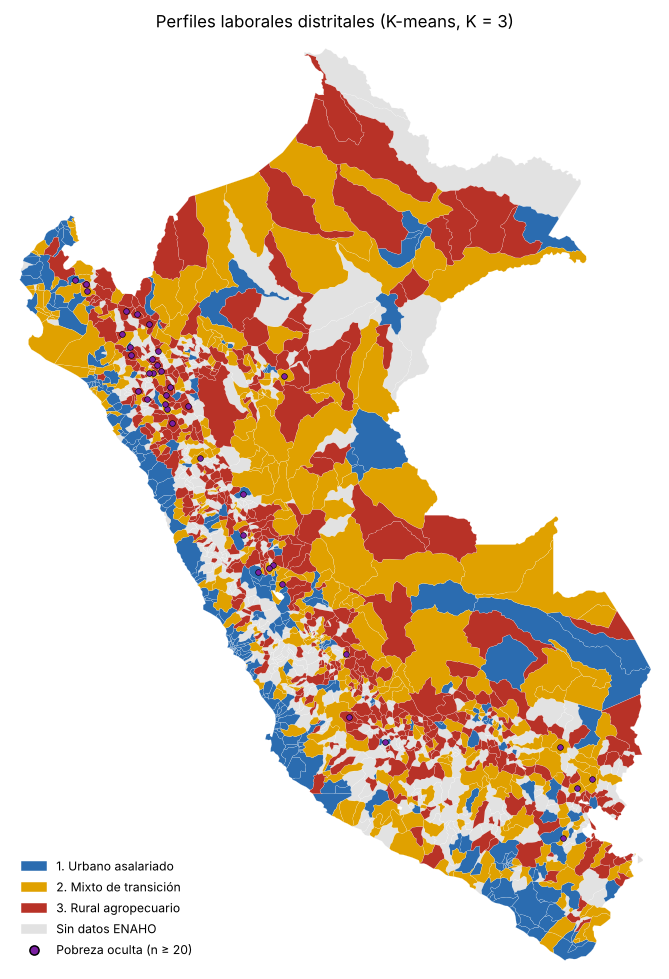

In [20]:
# Figura estática para el paper: todos los polígonos (gris = sin datos) coloreados por cluster
fig, ax = plt.subplots(figsize=(7, 9))
for grupo, color in [(None, "#e2e2e2"), (1, COLORES[1]), (2, COLORES[2]), (3, COLORES[3])]:
    polys = []
    for f in geo["features"]:
        u = f["properties"]["IDDIST"]
        c = int(info.loc[u, "cluster"]) if u in info.index else None
        if c == grupo: polys += [np.array(r) for r in anillos(f["geometry"])]
    ax.add_collection(PolyCollection(polys, facecolor=color, edgecolor="white", linewidth=0.1))
at = df[(df.atipico == "pobreza oculta") & con_geo]
ax.scatter(at.lon, at.lat, s=14, c="#7b1fa2", edgecolor="black", linewidth=.4, zorder=5, label="Pobreza oculta (n ≥ 20)")
ax.set_xlim(-81.5, -68.5); ax.set_ylim(-18.5, 0.2); ax.set_aspect("equal"); ax.axis("off")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLORES[k], label=NOMBRES[k]) for k in [1, 2, 3]] + [Patch(color="#e2e2e2", label="Sin datos ENAHO")]
          + [plt.Line2D([], [], marker="o", ls="", color="#7b1fa2", markeredgecolor="k", label="Pobreza oculta (n ≥ 20)")],
          loc="lower left", fontsize=8, frameon=False)
ax.set_title("Perfiles laborales distritales (K-means, K = 3)", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "h4_05_mapa_clusters.png", bbox_inches="tight", dpi=200); plt.show()

## 8. Exportar resultados

In [21]:
cols_out = ["UBIGEO", "DEPARTAMENTO", "PROVINCIA", "DISTRITO", "region_natural", "n_muestra", "lat", "lon",
            "cluster", "cluster_nombre", "silhouette", "margen", "ambiguo",
            "pobreza_pct", "pobreza_esperada", "residuo_pobreza", "atipico"] + VARS
df.assign(cluster_k4=k4, cluster_ward_k3=etiquetas["Ward K=3"], cluster_gmm_k3=etiquetas["GMM K=3"])[cols_out + ["cluster_k4", "cluster_ward_k3", "cluster_gmm_k3"]]\
  .to_csv(BASE / "output" / "resultados_hito4.csv", index=False, encoding="utf-8-sig")
print(sorted(p.name for p in OUT.iterdir()))

['reglas_arbol_profundidad2.txt', 't01_comparacion_final.csv', 't02_perfil_clusters.csv', 't03_eta2_variables.csv', 't04_arbol_surrogado.csv', 't05_pobreza_cluster_por_region.csv', 't06_correlacion_dentro_cluster.csv', 't07_r2_modelos_pobreza.csv', 't08_coeficientes_pobreza.csv', 't09_ambiguedad_por_cluster.csv', 't10_cluster2_nucleo_vs_ambiguo.csv', 't11_pobreza_oculta_top15.csv', 't12_mejor_de_lo_esperado_top15.csv', 't13_robustez_muestra.csv', 't14_departamentos.csv', 't15_perfil_k4.csv', 't16_autocorrelacion_espacial.csv']


## 9. Síntesis: hallazgos y evidencia
### Respuesta a la pregunta
**Sí existen perfiles laborales distritales diferenciados y se asocian con niveles distintos de pobreza, pero forman un gradiente continuo y no tipos naturales.** K-means (K = 3) separa 343 distritos urbano-asalariados, 430 mixtos y 497 rural-agropecuarios cuya pobreza mediana es 15.1 %, 31.0 % y 44.3 %, sin que la pobreza haya intervenido en el agrupamiento (ε² = 0.40).

| # | Hallazgo | Evidencia (tabla / figura) |
|---|---|---|
| 1 | La configuración final es K-means K = 3; ninguna alternativa (K = 2, K = 4, Ward, GMM, ponderado por muestra) la supera en el conjunto de criterios. | `t01`, `h4_01` |
| 2 | Los perfiles se definen por la estructura productiva (agro, informalidad, asalariados, educación); subempleo, sexo y edad no los separan. Un árbol de 2 niveles reproduce el 80 % de las asignaciones. | `t03`, `t04`, `h4_02` |
| 3 | La relación perfil–pobreza **no es solo geografía**: supera a la región natural (0.40 vs 0.27) y se repite dentro de Costa, Sierra y Selva. | `t05`, `h4_03` |
| 4 | La informalidad se asocia con la pobreza **entre perfiles**, no dentro de ellos (ρ = 0.58 total; ≈ 0 dentro del rural). La educación es la variable con mayor asociación propia. | `t06`–`t08`, `h4_04` |
| 5 | El grupo mixto es una zona de transición (26 % de distritos ambiguos, muchos con muestra chica). | `t09`, `t10` |
| 6 | Con muestras distritales más confiables la asociación con la pobreza **sube** (ε² 0.40 → 0.51): los resultados son conservadores. | `t13` |
| 7 | La tasa más alta está en el perfil rural, pero **la mitad de los pobres (≈ 51 %) vive en distritos del perfil urbano**. | `t02`, `t14` |
| 8 | 40 distritos confiables tienen *pobreza oculta* (sobre todo Cajamarca) y 34 están *mejor de lo esperado* (Selva baja, valles de Ica). | `t11`, `t12`, mapa |
| 9 | K = 4 añade un subsegmento rural de alto subempleo (157 distritos) sin diferencia de pobreza. | `t15` |
| 10 | Hay agrupamiento espacial (51 % de vecinos del mismo perfil vs 34 % al azar), sin regiones compactas. | `t16`, `h4_05`, `mapa_clusters.html` |

### Limitaciones
- **Estructura débil:** silhouette 0.17; los grupos son cortes de un gradiente.
- **Desfase temporal:** pobreza 2018 vs empleo 2024 → solo asociación, no causalidad.
- **Muestra distrital:** mediana de 23 encuestados; 105 distritos con < 10; el perfil rural tiene mediana de 16.
- **Cobertura:** 1,270 de 1,873 distritos (≈ 96 % de la población); 35 sin polígono en el mapa.
- **Una dimensión domina** (urbano–rural); el subempleo solo aparece con K = 4.
- **Pobres aproximados** = población 2020 × tasa 2018 (no es un conteo oficial).
- La partición depende del escalamiento (Hito 3: ARI 0.36 con `RobustScaler`); se justificó `StandardScaler`.

### Recomendaciones para el MTPE (insumo para el paper)
1. **Diferenciar la política por perfil:** perfil 1 → fiscalización y formalización de asalariados sin pensión; perfil 2 → transición (formalización de micro y pequeñas empresas, encadenamientos); perfil 3 → la informalidad está saturada: priorizar productividad agraria y protección social más que fiscalización.
2. **Combinar tasa y volumen** en la focalización: la mitad de los pobres está en distritos urbanos.
3. **Revisar caso por caso** los distritos ambiguos y los de *pobreza oculta* (Cajamarca) antes de asignarles una política tipo.
4. Usar la **regla de 3 variables** (agro, informalidad, asalariados) para clasificar distritos con nuevos datos.

### Trabajo futuro
Actualizar con un mapa de pobreza distrital más reciente; agregar ENAHO de varios años (pooling 2022–2024) para subir el tamaño de muestra distrital; incorporar variables de servicios y conectividad para explicar la pobreza oculta; clustering espacialmente restringido (p. ej., SKATER) para diseñar territorios de intervención.